In [1]:
import os
import glob
import numpy as np
import skimage.io, skimage.morphology
import matplotlib.pyplot as plt
import numba
import scipy.ndimage 

import csv
from multiprocessing import Manager, Lock
from concurrent.futures import ProcessPoolExecutor, as_completed

In [2]:
class Plate:

    def __init__(self, _name):
        self.name = _name
    
    def set_file_lists(self, _file_lists):
        self.fch1 = _file_lists[0]
        self.fch2 = _file_lists[1]
        self.fch3 = _file_lists[2]
        self.fch4 = _file_lists[3]

        assert(len(self.fch1) == len(self.fch2))
        assert(len(self.fch1) == len(self.fch3))
        assert(len(self.fch1) == len(self.fch4))
        self.num_images = len(self.fch1)
        

In [3]:
# Find all image pairs

BASE_DIR = "/media/user/SSD2/Athena/Hao_PRPC/PRPC/2025-07-09_60x_3plates/20250613 Lzso50screen/60x"
NUM_PLATES = 3

plates = []  # holds `plate` objects

for i in range(NUM_PLATES):

    plate_name = "plate%d" % (i+1)
    plate = Plate(plate_name)

    ch1_list = sorted(glob.glob("%s/%s_IJsplit/CH1/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch2_list = sorted(glob.glob("%s/%s_IJsplit/CH2/probabilities_cells/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch3_list = sorted(glob.glob("%s/%s_IJsplit/CH3/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))
    ch4_list = sorted(glob.glob("%s/%s_IJsplit/CH4/probabilities/*_Probabilities.tif" % (BASE_DIR, plate_name)))

    plate.set_file_lists([ch1_list, ch2_list, ch3_list, ch4_list])

    plates.append(plate)
    

In [13]:
def get_well_field(paths):
    well, field = paths[0].split("POM2_")[1].split("_")[0].split("-")
    return well, field


def pmap_to_mask(x):
    mask = np.zeros(x.shape, dtype=np.int32)
    mask[x>0.5] = 1
    return mask


def remove_small_holes(mask, area_threshold):
    mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)
    return mask


def remove_small_objects(mask, min_size):
    mask = skimage.morphology.remove_small_objects(ar=mask>0, min_size=min_size, connectivity=2).astype(np.int32) # If ar is bool, the image is first labeled
    return mask



# RDF

@numba.jit(nopython=True, parallel=False, fastmath=True)  # race condition with parallel=True
def get_rdf(Nbins, lyso, dist):
    nx,ny = lyso.shape
    dx = 2  # size of each bin in pixels
    L = Nbins * dx  # max number of pixels away from nucleus edge
    rdf = np.zeros(Nbins)
    for i in numba.prange(nx):
        for j in numba.prange(ny):
            q = int(dist[i,j] // dx)
            if q*dx < L:
                if lyso[i,j]>0:
                    rdf[q] += 1
    return rdf


def compute_rdf(Nbins, mask_nuc, mask_cel, mask_lys, debug=False):
    # distance of lysosomes to nearest nucleus
    distance_to_nuclei = scipy.ndimage.distance_transform_edt(mask_nuc==0)
    distance_to_nuclei[mask_cel==0] = 0
    if debug:
        print("distance_to_nuclei dtype:", distance_to_nuclei.dtype)
        plt.imshow(distance_to_nuclei)
        plt.colorbar()
        plt.show()

    # rdf of lysosomes in cells
    rdf = get_rdf(Nbins, mask_lys, distance_to_nuclei)
    if debug:
        plt.plot(np.arange(Nbins), rdf)
        plt.xlabel("number of bins from nearest nucleus")
        plt.ylabel("total lysosome area in pixels")
        plt.show()
    return rdf



In [14]:
def process_image_pair(paths, debug=False):

    for p in paths:
        print(os.path.basename(p))

    fnuc = paths[0]
    fcel = paths[1]
    flys = paths[2]
    fprp = paths[3]

    # load image files
    img_nuc = skimage.io.imread(fnuc, plugin='tifffile').astype(float)  # probability map from ilastik
    img_cel = skimage.io.imread(fcel, plugin='tifffile').astype(float)  # probability map from ilastik
    img_lys = skimage.io.imread(flys, plugin='tifffile').astype(float)  # probability map from ilastik
    img_prp = skimage.io.imread(fprp, plugin='tifffile').astype(float)  # probability map from ilastik

    # convert probability map to mask
    mask_nuc = pmap_to_mask(img_nuc)
    mask_cel = pmap_to_mask(img_cel)
    mask_lys = pmap_to_mask(img_lys)
    mask_prp = pmap_to_mask(img_prp)

    # remove small holes from nuclei and cell masks
    mask_nuc = remove_small_holes(mask_nuc, area_threshold=400)
    mask_cel = remove_small_holes(mask_cel, area_threshold=11000)

    # remove small disconnected artifacts in nucleus and cell masks
    mask_nuc = remove_small_objects(mask_nuc, min_size=1000)
    mask_cel = remove_small_objects(mask_cel, min_size=5000)
    if debug:
        print("dtypes after remove_small_objects:")
        print(mask_nuc.dtype)
        print(mask_cel.dtype)
        print("")

    # remove signal outside cells
    mask_nuc[mask_cel==0] = 0
    mask_lys[mask_cel==0] = 0
    mask_prp[mask_cel==0] = 0
    if debug:
        fig = plt.figure(figsize=(20,20))
        plt.subplot(1,5,1)
        plt.imshow(mask_nuc)
        plt.subplot(1,5,2)
        plt.imshow(mask_cel)
        plt.subplot(1,5,3)
        plt.imshow(mask_lys)
        plt.subplot(1,5,4)
        plt.imshow(mask_prp)
        plt.subplot(1,5,5)
        plt.imshow(img_cel, cmap="gray")
        plt.show()
        print(mask_nuc.dtype)
        print(mask_cel.dtype)
        print(mask_lys.dtype)
        print(mask_prp.dtype)

    # Compute total area per structure
    area_nuc = np.sum(mask_nuc)
    area_cel = np.sum(mask_cel)
    area_lys = np.sum(mask_lys)
    area_prp = np.sum(mask_prp)

    if debug:
        well, field = get_well_field(paths)
        print("well", well)
        print("field", field)
        print("area_nuc", area_nuc, area_nuc==np.sum(mask_nuc>0), float(area_nuc)/(mask_nuc.shape[0]*mask_nuc.shape[1]))
        print("area_cel", area_cel, area_cel==np.sum(mask_cel>0), float(area_cel)/(mask_cel.shape[0]*mask_cel.shape[1]))
        print("area_lys", area_lys, area_lys==np.sum(mask_lys>0), float(area_lys)/(mask_lys.shape[0]*mask_lys.shape[1]))
        print("area_prp", area_prp, area_prp==np.sum(mask_prp>0), float(area_prp)/(mask_prp.shape[0]*mask_prp.shape[1]))


    # Compute distribution of prpc inside cells
    


    # Compute rdf of lysosomes from nearest nucleus
    NBINS = 150
    if area_nuc>0 and area_lys>0:
        rdf = compute_rdf(NBINS, mask_nuc, mask_cel, mask_lys, debug)
    else:
        rdf = np.zeros(NBINS)

    return area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cytoplasm, total_prpc_celledge, total_prpc_lysosome, rdf


    

20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH1_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH2_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH3_Probabilities.tif
20250614_60x_4CLyso_405DAPI_488CellMask_561LAMP1_647POM2_B10-10_1215CH4_Probabilities.tif
dtypes after remove_small_objects:
int32
int32



/tmp/ipykernel_2122670/571376397.py:13: UserWarning: Any labeled images will be returned as a boolean array. Did you mean to use a boolean array?
  mask = skimage.morphology.remove_small_holes(mask, area_threshold=area_threshold).astype(np.int32)


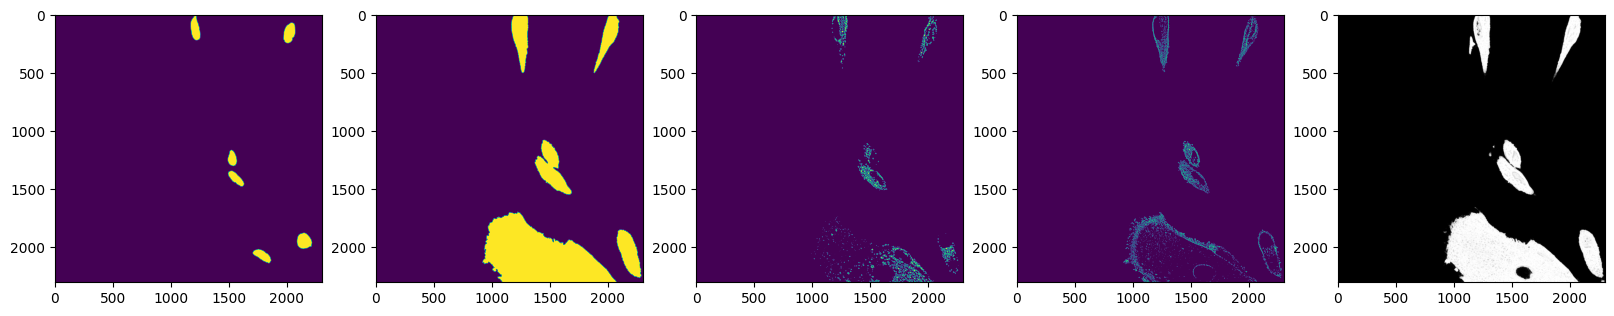

int32
int32
int32
int32
well B10
field 10
area_nuc 66403 True 0.012509004569347993
area_cel 615687 True 0.1159831859447338
area_lys 51404 True 0.009683491271219136
area_prp 56066 True 0.010561719352816358
distance_to_nuclei dtype: float64


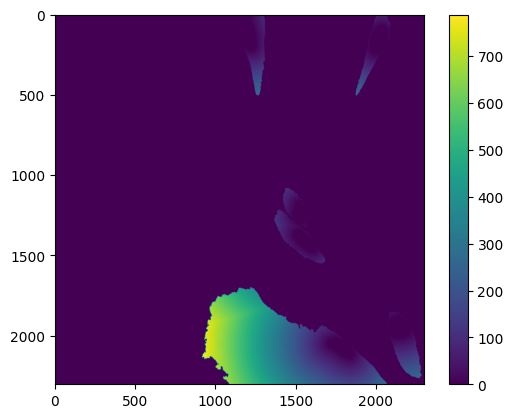

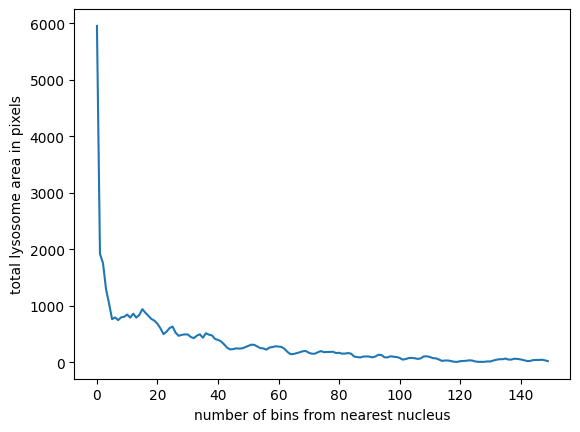

NameError: name 'total_prpc_nucleus' is not defined

In [15]:
# Loop over plates and images - SINGLE PROCESS - TESTING

for plate in plates:
    for paths in zip(plate.fch1, plate.fch2, plate.fch3, plate.fch4):
        area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cytoplasm, total_prpc_celledge, total_prpc_lysosome, rdf = process_image_pair(paths, debug=True)
        
        assert(0)


In [ ]:
assert(0)

In [ ]:
def process_images_multi(args, shared_list, lock):

    plate_name = args[0]
    paths = args[1]

    area_nuc, area_cel, area_lys, area_prp, total_prpc_nucleus, total_prpc_cytoplasm, total_prpc_celledge, total_prpc_lysosome, rdf = process_image_pair(paths)

    # get row, column from file name
    well, field = get_well_field(paths)
    row = well[0]
    col = int(well[1::])

    result = {
        "Plate": plate_name,
        "File": os.path.basename(paths[0]),
        "Well": well,
        "Row": row,
        "Column": col,
        "AreaNuclei": area_nuc,
        "AreaCells": area_cel,
        "AreaLyso": area_lys,
        "AreaPrPC": area_prp,
        "PrPc_in_DAPI": total_prpc_nucleus,
        "PrPc_in_Cytoplasm": total_prpc_cytoplasm,
        "PrPc_in_CellEdge": total_prpc_celledge,
        "PrPc_in_Lysosome": total_prpc_lysosome,
        "LysosomeRDF": ",".join(map(str,rdf))
    }

    with lock:
        shared_list.append(result)
    

In [ ]:
# Loop over plates and images - MULTI PROCESSING

max_workers = 64
output_file_prefix = "output_2025-08-21_60x"


for plate in plates:
    plate_name = plate.name
    print("PROCESSING PLATE:", plate_name)

    Nfiles = plate.num_images

    output_file = "%s_%s.csv" % (output_file_prefix, plate_name)

    with Manager() as manager:
        shared_list = manager.list()
        lock = manager.Lock()

        with ProcessPoolExecutor(max_workers=max_workers) as executor:
            futures = [
                executor.submit(process_images_multi, [plate_name, paths], shared_list, lock)
                for paths in zip(plate.fch1, plate.fch2, plate.fch3, plate.fch4)
            ]
            for i,future in enumerate(as_completed(futures), 1):
                future.result()
                if i%10==0 or i==Nfiles:
                    print(f"Processed {i}/{Nfiles} images")

        header = ["Plate", "File", "Well", "Row", "Column",
                    "AreaNuclei", "AreaCells", "AreaLyso", "AreaPrPC", 
                    "PrPc_in_DAPI", "PrPc_in_Cytoplasm", "PrPc_in_CellEdge", "PrPc_in_Lysosome",
                    "LysosomeRDF"]

        with open(output_file, 'w', newline='\n') as f:
            writer = csv.DictWriter(f, fieldnames=header)
            writer.writeheader()
            for row in shared_list:
                writer.writerow(row)